In [24]:
#1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("lab_ticket_resolution.csv")
print("Dataset shape:")
print(df.shape)
print("\nData types:")
print(df.dtypes)
print("\nDescriptive statistics:")
print(df.describe(include="all"))
print("\nMissing values:")
print(df.isna().sum())
print("\nFirst five rows:")
display(df.head())

Dataset shape:
(240, 6)

Data types:
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54

,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


In [20]:
#2
y = df["resolution_hours"]  
X = df.drop(columns=["resolution_hours", "ticket_id"], errors="ignore") 

print("Target (y):", y.name)
print("Feature columns:", X.columns.tolist())
print("\nNumber of features:", X.shape[1])

Target (y): resolution_hours
Feature columns: ['complexity_score', 'lines_changed', 'team_experience_years', 'reopened']

Number of features: 4


In [21]:
#3
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42  
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (192, 4)
Testing features: (48, 4)
Training targets: (192,)
Testing targets: (48,)


In [22]:
#4
def evaluate_model(name, model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    mae = mean_absolute_error(y_eval, predictions)
    mse = mean_squared_error(y_eval, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_eval, predictions)
    return {"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_results = evaluate_model("Dummy Baseline", baseline, X_test, y_test)
print(baseline_results)

{'Model': 'Dummy Baseline', 'MAE': 9.113951822916667, 'MSE': 112.31092313639323, 'RMSE': np.float64(10.597684800766308), 'R2': -0.021016765260001957}


In [25]:
#5
inear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_results = evaluate_model("Linear Regression", linear_model, X_test, y_test)
print(linear_results)

{'Model': 'Linear Regression', 'MAE': 2.560450831183051, 'MSE': 9.948133924280496, 'RMSE': np.float64(3.154066252360672), 'R2': 0.9095616772074165}


Cross-validation results:


,Polynomial Degree,Mean CV RMSE,Standard Deviation
0,1,3.5267,0.2517
1,2,3.6768,0.1416
2,3,4.1719,0.4479
3,4,10.3213,8.5990


Best polynomial degree based on CV RMSE: 1
Test metrics and cross-validation comparison:


,MAE,MSE,RMSE,R2,Mean CV RMSE,Train RMSE
Model,,,,,,
Polynomial Degree 1,2.5605,9.9481,3.1541,0.9096,3.5267,3.4514
Polynomial Degree 2,2.8843,12.9704,3.6014,0.8821,3.6768,3.3162
Polynomial Degree 3,3.1814,16.0258,4.0032,0.8543,4.1719,3.1887
Polynomial Degree 4,4.1731,33.8162,5.8152,0.6926,10.3213,2.9039


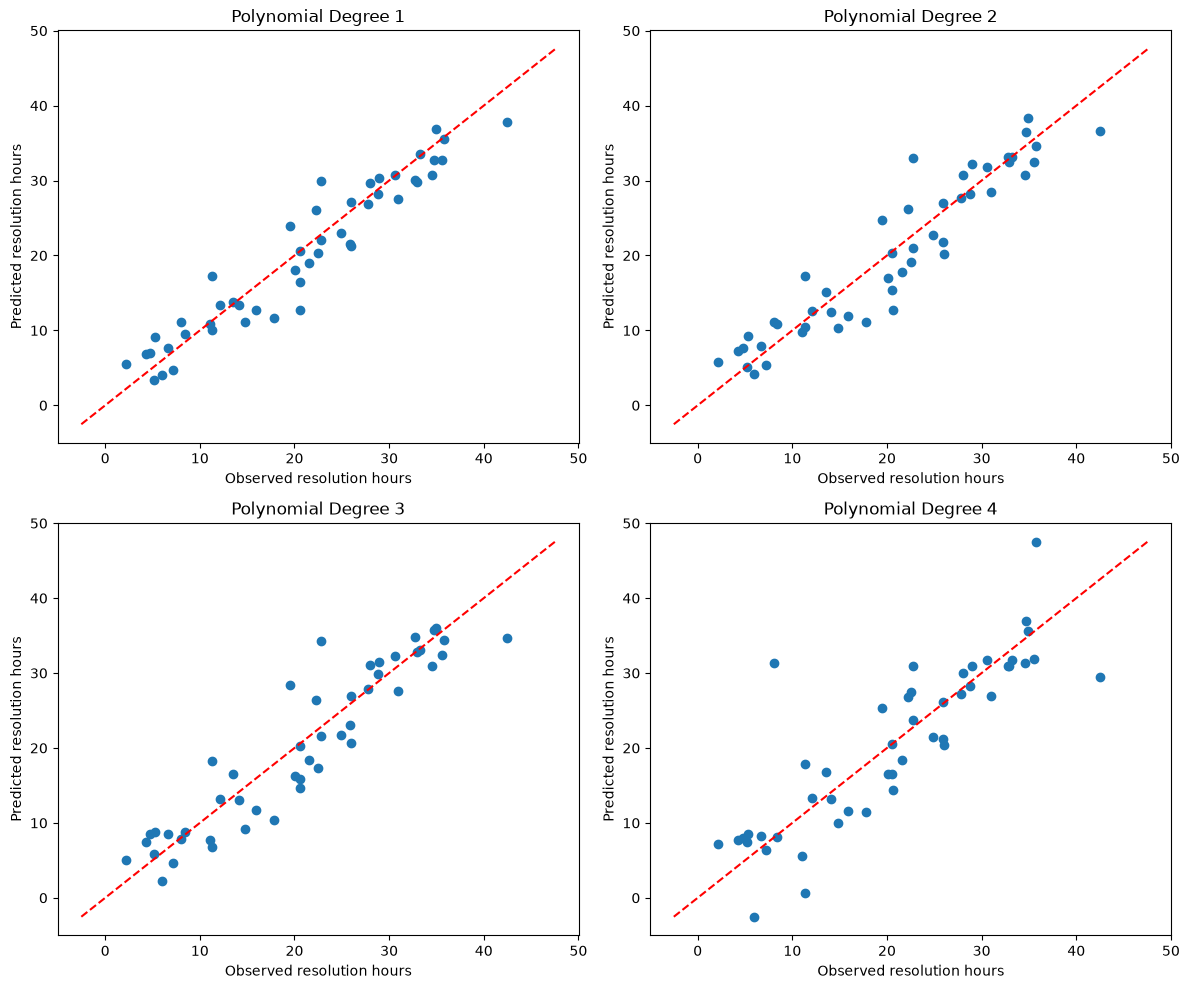

In [26]:
#6
cv = KFold(n_splits=5, shuffle=True, random_state=42)

degree_results = []
degree_models = {}

for degree in [1, 2, 3, 4]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    cv_scores = -cross_val_score(
        model, X_train, y_train, cv=cv,
        scoring="neg_root_mean_squared_error"
    )
    degree_results.append({
        "Polynomial Degree": degree,
        "Mean CV RMSE": cv_scores.mean(),
        "Standard Deviation": cv_scores.std()
    })
    degree_models[degree] = model

degree_df = pd.DataFrame(degree_results)
print("Cross-validation results:")
display(degree_df.round(4))

best_degree = int(degree_df.loc[degree_df["Mean CV RMSE"].idxmin(), "Polynomial Degree"])
print("Best polynomial degree based on CV RMSE:", best_degree)

test_results = []

for degree, model in degree_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    train_rmse = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))

    test_results.append({
        "Model": f"Polynomial Degree {degree}",
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
        "Mean CV RMSE": degree_df.loc[
            degree_df["Polynomial Degree"] == degree, "Mean CV RMSE"].iloc[0],
        "Train RMSE": train_rmse
    })

test_results_df = pd.DataFrame(test_results).set_index("Model")
print("Test metrics and cross-validation comparison:")
display(test_results_df.round(4))
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

low = min(y_test.min(), min(degree_models[d].predict(X_test).min() for d in degree_models))
high = max(y_test.max(), max(degree_models[d].predict(X_test).max() for d in degree_models))

for i, degree in enumerate([1, 2, 3, 4]):
    predictions = degree_models[degree].predict(X_test)
    axes[i].scatter(y_test, predictions)
    axes[i].plot([low, high], [low, high], "r--")
    axes[i].set_xlabel("Observed resolution hours")
    axes[i].set_ylabel("Predicted resolution hours")
    axes[i].set_title(f"Polynomial Degree {degree}")

plt.tight_layout()
plt.show()

In [27]:
#7
alphas = np.logspace(-3, 3, 50)

regularization_results = []
regularization_models = {}

for name, estimator in [("Ridge", Ridge()), ("Lasso", Lasso(max_iter=100000))]:
    pipeline = make_pipeline(StandardScaler(), estimator)

    search = GridSearchCV(
        pipeline,
        param_grid={f"{name.lower()}__alpha": alphas},
        scoring="neg_root_mean_squared_error",
        cv=cv
    )
    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    predictions = best_model.predict(X_test)
    mse = mean_squared_error(y_test, predictions)

    regularization_models[name] = best_model
    regularization_results.append({
        "Model": name,
        "Selected Alpha": search.best_params_[f"{name.lower()}__alpha"],
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, predictions),
        "Mean CV RMSE": -search.best_score_
    })

regularization_df = pd.DataFrame(regularization_results).set_index("Model")
display(regularization_df.round(4))

lin_scaled = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
print("Linear:", dict(zip(X.columns, lin_scaled[-1].coef_.round(4))))
for name, m in regularization_models.items():
    print(name + ":", dict(zip(X.columns, m[-1].coef_.round(4))))

,Selected Alpha,MAE,MSE,RMSE,R2,Mean CV RMSE
Model,,,,,,
Ridge,0.001,2.5604,9.9481,3.1541,0.9096,3.5267
Lasso,0.001,2.5606,9.9500,3.1544,0.9095,3.5267


Linear: {'complexity_score': np.float64(8.003), 'lines_changed': np.float64(0.7073), 'team_experience_years': np.float64(-1.1582), 'reopened': np.float64(1.8074)}
Ridge: {'complexity_score': np.float64(8.0027), 'lines_changed': np.float64(0.7075), 'team_experience_years': np.float64(-1.1582), 'reopened': np.float64(1.8075)}
Lasso: {'complexity_score': np.float64(8.0069), 'lines_changed': np.float64(0.7029), 'team_experience_years': np.float64(-1.1571), 'reopened': np.float64(1.8061)}


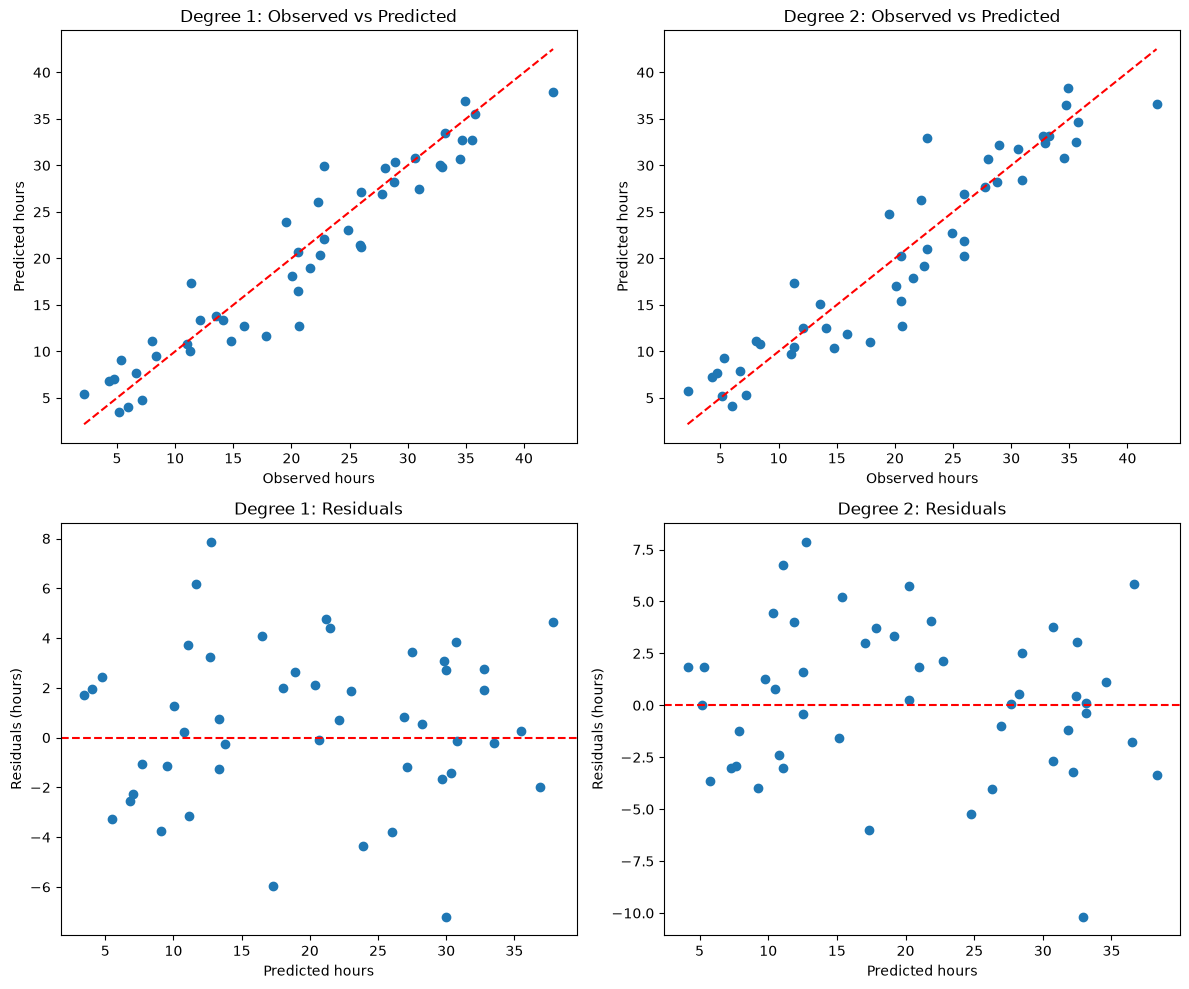

,MAE,MSE,RMSE,R2,Mean CV RMSE
Model,,,,,
Baseline,9.1140,112.3109,10.5977,-0.0210,9.8839
Linear (2 features),2.9060,12.7611,3.5723,0.8840,3.9092
Polynomial Degree 2 (2 features),3.0202,13.9944,3.7409,0.8728,3.8325
Polynomial Degree 3 (2 features),3.1398,15.5936,3.9489,0.8582,3.8766
Ridge (2 features),2.9056,12.7543,3.5713,0.8841,3.9091
Lasso (2 features),2.9061,12.7612,3.5723,0.8840,3.9093


RMSE improvement of linear model over baseline: 66.3%


In [28]:
#8
diagnostic_models = {}

for degree in [1, 2]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    model.fit(X_train, y_train)
    diagnostic_models[f"Degree {degree}"] = (model, model.predict(X_test))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for col, (name, (model, predictions)) in enumerate(diagnostic_models.items()):
    # Observed versus predicted
    axes[0, col].scatter(y_test, predictions)
    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())
    axes[0, col].plot([low, high], [low, high], "r--")
    axes[0, col].set_title(f"{name}: Observed vs Predicted")
    axes[0, col].set_xlabel("Observed hours")
    axes[0, col].set_ylabel("Predicted hours")

    residuals = y_test - predictions
    axes[1, col].scatter(predictions, residuals)
    axes[1, col].axhline(0, color="red", linestyle="--")
    axes[1, col].set_title(f"{name}: Residuals")
    axes[1, col].set_xlabel("Predicted hours")
    axes[1, col].set_ylabel("Residuals (hours)")

plt.tight_layout()
plt.show()

safe_features = ["complexity_score", "team_experience_years"]
Xs_train, Xs_test = X_train[safe_features], X_test[safe_features]

rows = []
def add(name, model, alpha=None):
    model.fit(Xs_train, y_train)
    p = model.predict(Xs_test)
    mse = mean_squared_error(y_test, p)
    cvr = -cross_val_score(model, Xs_train, y_train, cv=cv,
                           scoring="neg_root_mean_squared_error").mean()
    rows.append({"Model": name, "MAE": mean_absolute_error(y_test, p), "MSE": mse,
                 "RMSE": np.sqrt(mse), "R2": r2_score(y_test, p), "Mean CV RMSE": cvr})

add("Baseline", DummyRegressor(strategy="mean"))
add("Linear (2 features)", LinearRegression())
for d in [2, 3]:
    add(f"Polynomial Degree {d} (2 features)",
        make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression()))
for name, est in [("Ridge", Ridge()), ("Lasso", Lasso(max_iter=100000))]:
    s = GridSearchCV(make_pipeline(StandardScaler(), est),
                     {f"{name.lower()}__alpha": alphas}, cv=cv,
                     scoring="neg_root_mean_squared_error").fit(Xs_train, y_train)
    add(f"{name} (2 features)", s.best_estimator_)

safe_df = pd.DataFrame(rows).set_index("Model")
display(safe_df.round(4))
base_rmse = safe_df.loc["Baseline", "RMSE"]
lin_rmse = safe_df.loc["Linear (2 features)", "RMSE"]
print("RMSE improvement of linear model over baseline: %.1f%%" % ((base_rmse - lin_rmse) / base_rmse * 100))

9.
I would choose the simple linear model (Degree 1). It had the lowest errors (MAE 2.5605, RMSE 3.1541), the best R² (0.9096), and the best cross-validation score (3.5267). It is also much better than the baseline, which had an RMSE of 10.5977. Polynomial models, Ridge, and Lasso did not do any better.
Before using it , I would remove lines_changed and reopened, because they are not known when a ticket first arrives. I would test it on newer tickets, check the residual plots again, and confirm the data looks like real ticket data, since this dataset is synthetic.

10.
The baseline is a simple starting point. It guesses the average resolution time for every ticket. The baseline had an RMSE of 10.5977 and an R² of about 0. the linear model had an RMSE of 3.1541 which is about 70.2% better. This shows the features are useful for prediction.

11.
Degree 1  had the lowest MAE 2.5605 and the lowest RMSE 3.1541, so it is the same model for both. Ridge and Lasso were almost exactly the same. MAE and RMSE can give different winners because RMSE punishes big mistakes more than small ones. A model with a few very large errors can have an good MAE but a much worse RMSE.

12.
No. Higher degrees made the results worse.As the degree goes up, the training error gets smaller, but the test error and CV error get bigger. This means the model is memorizing the training data instead of learning the real pattern, which is overfitting. It is worst at Degree 4 where the CV RMSE is 10.3213.

13.
Regularization made  no difference. Cross-validation chose a very small alpha 0.001 for both Ridge and Lasso, so the penalty was zero. Their results were the same as linear regression RMSE  3.154, R² 0.9096. The coefficients also stayed  the same, and Lasso did not remove any feature. This is because the dataset is small and simple, with only four features, so the model was not overfitting and did not need a penalty.

14.
The features have very different sizes. Ridge and Lasso penalize large coefficients, so without scaling the penalty would be unfair to some features. Scaling puts all features on the same level. I put the scaler inside a pipeline so it only learns from the training data and not from the test data, which prevents data leakage.

15.
The main leakage risk is reopened. A ticket can only be reopened after it has already been worked on, so we would not know this when the ticket first arrives. lines_changed has the same problem because it is only known after the fix is made. I removed ticket_id because it is only an ID, and I kept the other features so I could compare the models. This means main scores are probably a more good. and also I ran the leakage check above using  complexity_score and team_experience_years. The linear model then had an RMSE of 3.5723 instead of 3.1541 so the all-feature results were slightly more optimistic. Before real use, I would remove reopened and lines_changed.

16.
No,  A random split is fine for a simple test, but it is not ideal here. Ticket patterns change over time and a random split mixes old and new tickets in both the training and test sets. So the test result does not show how the model would do on future tickets. Tickets from the same customer or team are also similar to each other, so the same kind of ticket could appear in both sets, which makes the results look better than they are. A better way is to train on older tickets and test on newer ones. I would also keep each customer or team in only one set.

17.
- Test it on newer tickets that the model has never seen.
- Check again that I only use features known when the ticket arrives.
- Look at the residual plots to find patterns, uneven errors, or outliers.
- Use a time-based or group-based split to check the results hold up.
- Check how the model handles missing, unusual, or invalid values.
- Confirm it is still clearly better than the baseline on the new data.
- Keep tracking its errors after deployment, and retrain if ticket patterns change.